# Análisis Comparativo: Datos Originales vs Redistribución con Pre-Asignación

Compara las métricas semanales reales del hospital (groundtruth) contra los escenarios simulados de redistribución con pre-asignación aleatoria.

**Prerequisitos:**
- `python src/metricas_originales.py` → genera `data/resultados_baseline.csv`
- `python src/experimento_preasignacion.py` → genera `data/resultados_experimento_preasignacion.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

ROOT       = Path('../..')
DATA_DIR   = ROOT / 'data'
OUTPUT_DIR = ROOT / 'output' / 'analisis_comparativo_preasignacion'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = {
    'baseline' : '#1565C0',
    'sim'      : '#D32F2F',
    'preassign': '#F57C00',
    'urg'      : '#E53935',
    'elec'     : '#1E88E5',
    'neutral'  : '#546E7A',
}

HEU_PAL = {'FIFO': '#4878CF', 'SPT': '#53A76F', 'LPT': '#D65F5F'}
RATE_LABEL = {0.00: '0%', 0.05: '5%', 0.10: '10%', 0.15: '15%', 0.20: '20%'}

def save(name: str):
    path = OUTPUT_DIR / f'{name}.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Guardado: {path}')

In [2]:
# Non-pandemic cutoff parameter
CUTOFF   = '2022-01-01'
COLOR_NP = '#1D9E75'

In [3]:
# Carga de datos
bl = pd.read_csv(DATA_DIR / 'resultados_baseline.csv', parse_dates=['weekStart'])
bl = bl.sort_values('weekStart').reset_index(drop=True)

sim_path = DATA_DIR / 'resultados_experimento_preasignacion.csv'
sim = pd.read_csv(sim_path) if sim_path.exists() else None

print(f'Baseline: {len(bl)} semanas  ({bl["weekStart"].min().date()} \u2013 {bl["weekStart"].max().date()})')
if sim is not None:
    print(f'Experimento Pre-Asignacion: {len(sim):,} filas  |  {sim["iteracion"].nunique()} ventanas')
    print(f'Tasas de insercion: {sorted(sim["random_rate"].unique())}')
bl.head()

bl_np = bl[bl['weekStart'] >= CUTOFF].copy()
print(f'Non-pandemic (>= {CUTOFF}): {len(bl_np)} weeks')

Baseline: 209 semanas  (2019-12-30 – 2023-12-25)
Experimento Pre-Asignacion: 6,150 filas  |  205 ventanas
Tasas de insercion: [np.float64(0.0), np.float64(0.05), np.float64(0.1), np.float64(0.15), np.float64(0.2)]
Non-pandemic (>= 2022-01-01): 104 weeks


## 1. Throughput semanal — serie temporal

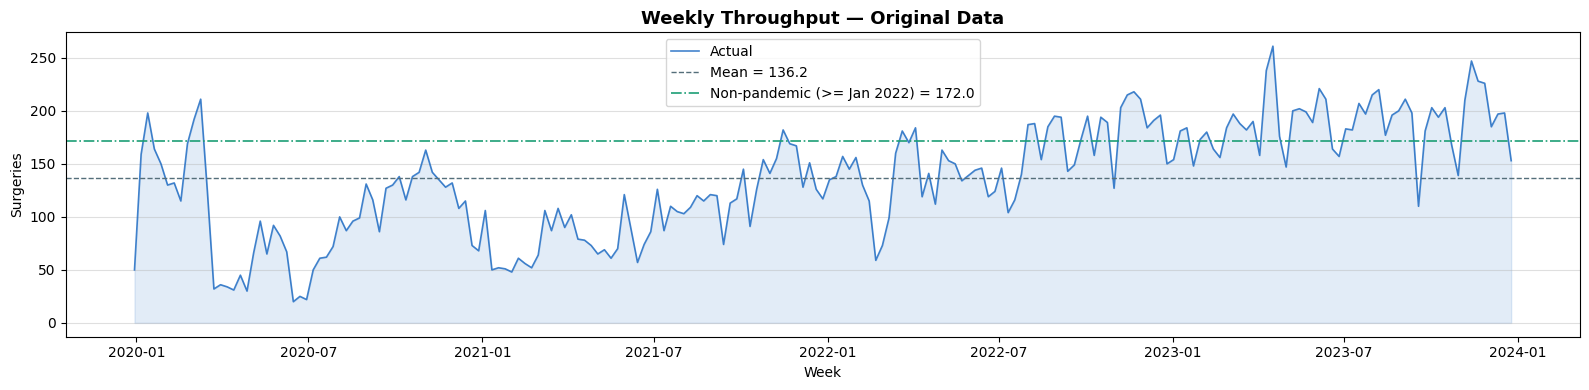

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_throughput_serie.png


In [4]:
fig, ax = plt.subplots(figsize=(16, 4))

ax.plot(bl['weekStart'], bl['totalSurgeries'],
        color=PALETTE['baseline'], linewidth=1.2, alpha=0.8, label='Actual')
ax.fill_between(bl['weekStart'], bl['totalSurgeries'],
                alpha=0.12, color=PALETTE['baseline'])

mean_tp = bl['totalSurgeries'].mean()
ax.axhline(mean_tp, color=PALETTE['neutral'], linestyle='--', linewidth=1,
           label=f'Mean = {mean_tp:.1f}')

mean_tp_np = bl_np['totalSurgeries'].mean()
ax.axhline(mean_tp_np, color=COLOR_NP, linestyle='-.', linewidth=1.2,
           label=f'Non-pandemic (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {mean_tp_np:.1f}')

ax.set_title('Weekly Throughput \u2014 Original Data', fontsize=13, fontweight='bold')
ax.set_xlabel('Week'); ax.set_ylabel('Surgeries')
ax.legend()
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
save('cmp_pa_throughput_serie')

## 2. Lead time semanal — serie temporal

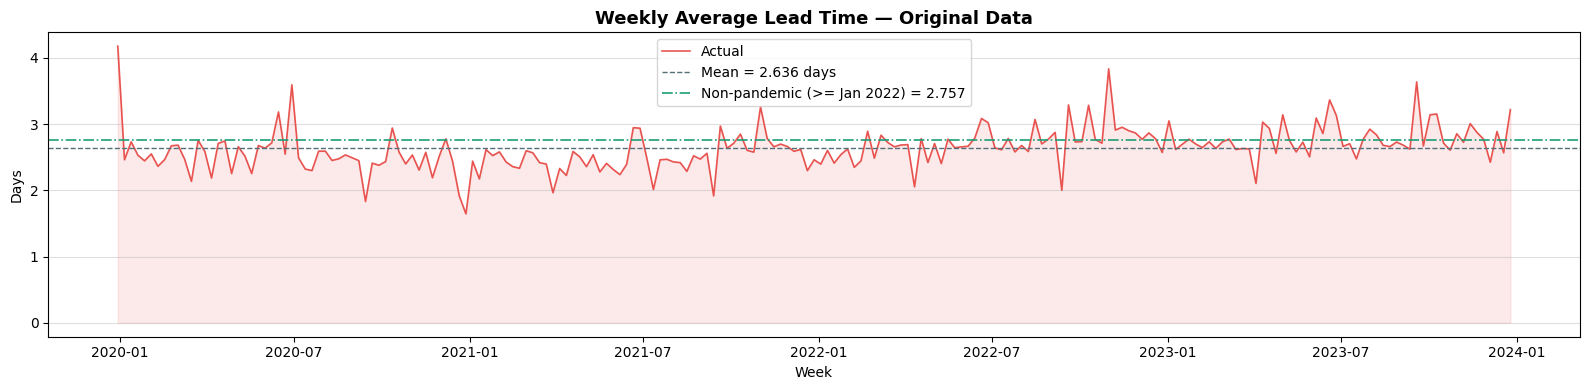

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_leadtime_serie.png


In [5]:
fig, ax = plt.subplots(figsize=(16, 4))

ax.plot(bl['weekStart'], bl['avgLeadTimeDays'],
        color=PALETTE['urg'], linewidth=1.2, alpha=0.85, label='Actual')
ax.fill_between(bl['weekStart'], bl['avgLeadTimeDays'],
                alpha=0.1, color=PALETTE['urg'])

mean_lt = bl['avgLeadTimeDays'].mean()
ax.axhline(mean_lt, color=PALETTE['neutral'], linestyle='--', linewidth=1,
           label=f'Mean = {mean_lt:.3f} days')

mean_lt_np = bl_np['avgLeadTimeDays'].mean()
ax.axhline(mean_lt_np, color=COLOR_NP, linestyle='-.', linewidth=1.2,
           label=f'Non-pandemic (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {mean_lt_np:.3f}')

ax.set_title('Weekly Average Lead Time \u2014 Original Data', fontsize=13, fontweight='bold')
ax.set_xlabel('Week'); ax.set_ylabel('Days')
ax.legend()
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
save('cmp_pa_leadtime_serie')

## 3. Utilización semanal — serie temporal (Urg / Elec / Global)

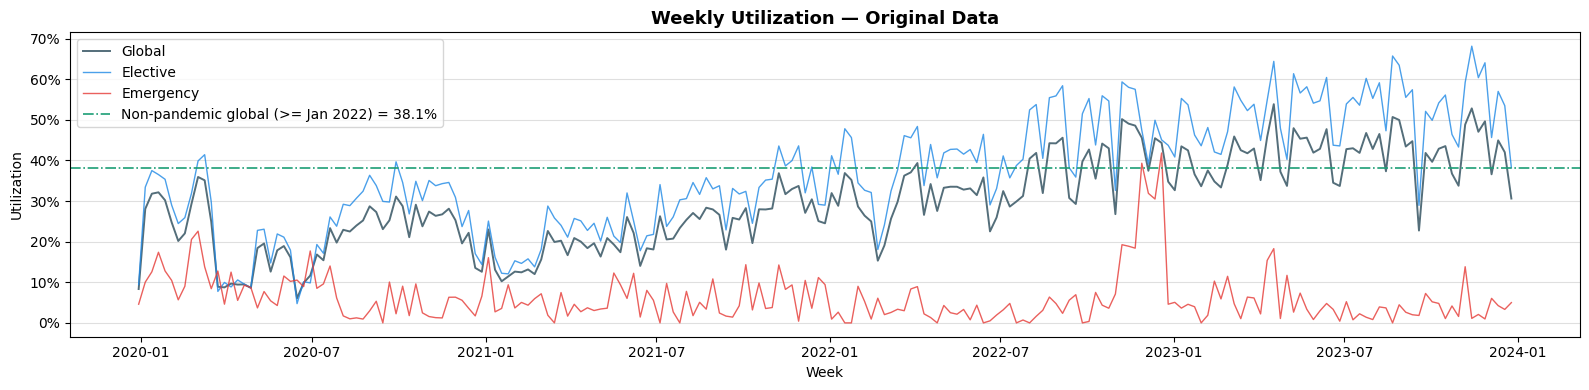

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_utilizacion_serie.png


In [6]:
fig, ax = plt.subplots(figsize=(16, 4))

ax.plot(bl['weekStart'], bl['utilGlobal_pct'], color=PALETTE['neutral'],
        linewidth=1.4, label='Global')
ax.plot(bl['weekStart'], bl['utilElec_pct'], color=PALETTE['elec'],
        linewidth=1, alpha=0.8, label='Elective')
ax.plot(bl['weekStart'], bl['utilUrg_pct'], color=PALETTE['urg'],
        linewidth=1, alpha=0.8, label='Emergency')

util_glob_np = bl_np['utilGlobal_pct'].mean()
ax.axhline(util_glob_np, color=COLOR_NP, linestyle='-.', linewidth=1.2,
           label=f'Non-pandemic global (>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}) = {util_glob_np:.1f}%')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_title('Weekly Utilization \u2014 Original Data', fontsize=13, fontweight='bold')
ax.set_xlabel('Week'); ax.set_ylabel('Utilization')
ax.legend()
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
save('cmp_pa_utilizacion_serie')

## 4. Distribución de métricas originales

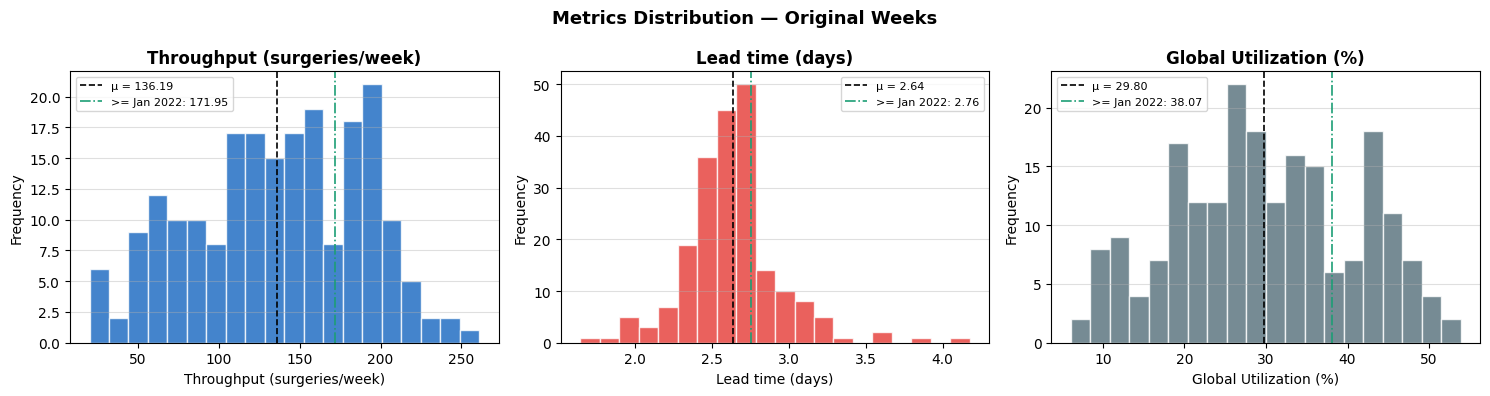

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_distribucion_baseline.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ('totalSurgeries',  'Throughput (surgeries/week)', PALETTE['baseline']),
    ('avgLeadTimeDays', 'Lead time (days)',             PALETTE['urg']),
    ('utilGlobal_pct',  'Global Utilization (%)',       PALETTE['neutral']),
]

for ax, (col, label, color) in zip(axes, metrics):
    data = bl[col].dropna()
    ax.hist(data, bins=20, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(data.mean(), color='black', linestyle='--', linewidth=1.2,
               label=f'\u03bc = {data.mean():.2f}')
    data_np = bl_np[col].dropna()
    ax.axvline(data_np.mean(), color=COLOR_NP, linestyle='-.', linewidth=1.2,
               label=f'>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}: {data_np.mean():.2f}')
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel(label); ax.set_ylabel('Frequency')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.4)

fig.suptitle('Metrics Distribution \u2014 Original Weeks', fontsize=13, fontweight='bold')
plt.tight_layout()
save('cmp_pa_distribucion_baseline')

## 5. Urgencias vs Electivas — composición semanal

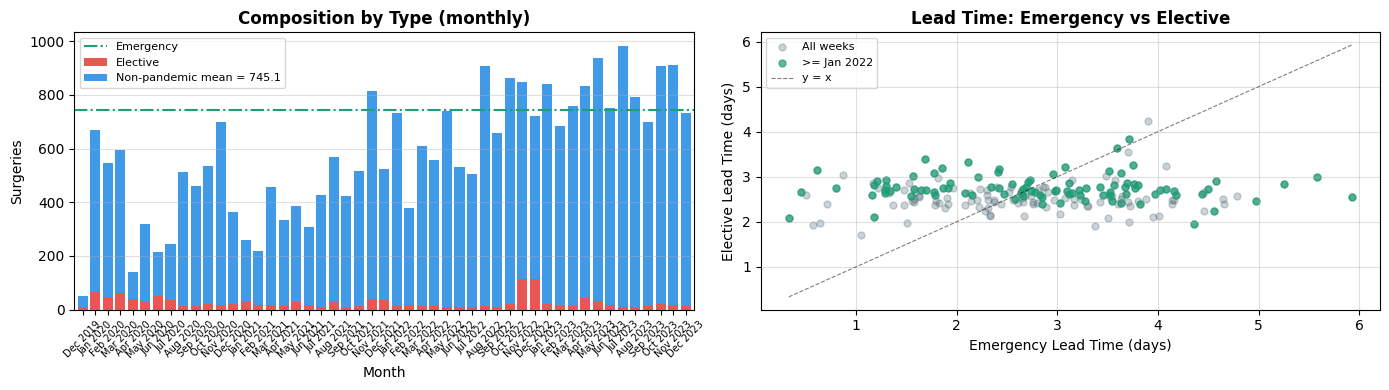

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_composicion_leadtime.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
sample = (bl[['weekStart', 'urgSurgeries', 'elecSurgeries']]
          .set_index('weekStart')
          .resample('MS').sum())
sample.index = sample.index.strftime('%b %Y')
sample.plot(kind='bar', stacked=True, ax=ax,
            color=[PALETTE['urg'], PALETTE['elec']], alpha=0.85, width=0.8)
ax.set_title('Composition by Type (monthly)', fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('Surgeries')
ax.tick_params(axis='x', rotation=45, labelsize=7)
ax.grid(axis='y', alpha=0.4)
np_mean_total = (bl_np[['weekStart', 'urgSurgeries', 'elecSurgeries']]
                 .set_index('weekStart')
                 .resample('MS').sum()
                 .sum(axis=1).mean())
ax.axhline(np_mean_total, color=COLOR_NP, linestyle='-.', linewidth=1.5,
           label=f'Non-pandemic mean = {np_mean_total:.1f}')
ax.legend(['Emergency', 'Elective', f'Non-pandemic mean = {np_mean_total:.1f}'], fontsize=8)

ax2 = axes[1]
ax2.scatter(bl['avgLeadTimeUrg'], bl['avgLeadTimeElec'],
            color=PALETTE['neutral'], alpha=0.3, s=25, label='All weeks')
ax2.scatter(bl_np['avgLeadTimeUrg'], bl_np['avgLeadTimeElec'],
            color=COLOR_NP, alpha=0.7, s=25,
            label=f'>= {pd.Timestamp(CUTOFF).strftime("%b %Y")}')
lims = [min(bl[['avgLeadTimeUrg', 'avgLeadTimeElec']].min()),
        max(bl[['avgLeadTimeUrg', 'avgLeadTimeElec']].max())]
ax2.plot(lims, lims, 'k--', linewidth=0.8, alpha=0.5, label='y = x')
ax2.set_title('Lead Time: Emergency vs Elective', fontweight='bold')
ax2.set_xlabel('Emergency Lead Time (days)')
ax2.set_ylabel('Elective Lead Time (days)')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.4)

plt.tight_layout()
save('cmp_pa_composicion_leadtime')

## 6. Throughput top vs bottom semanas

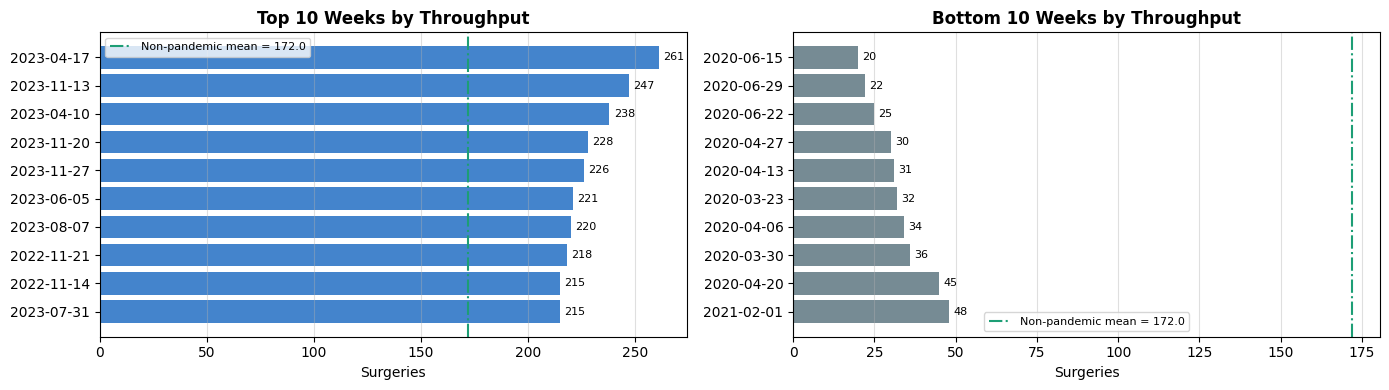

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_top_bottom_semanas.png


In [9]:
n = 10
top    = bl.nlargest(n,  'totalSurgeries')[['weekStart', 'totalSurgeries', 'utilGlobal_pct', 'avgLeadTimeDays']]
bottom = bl.nsmallest(n, 'totalSurgeries')[['weekStart', 'totalSurgeries', 'utilGlobal_pct', 'avgLeadTimeDays']]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, data, label, color in [
    (axes[0], top,    f'Top {n} Weeks by Throughput',    PALETTE['baseline']),
    (axes[1], bottom, f'Bottom {n} Weeks by Throughput', PALETTE['neutral']),
]:
    weeks = data['weekStart'].dt.strftime('%Y-%m-%d')
    bars = ax.barh(weeks, data['totalSurgeries'], color=color, alpha=0.8)
    ax.bar_label(bars, fmt='%d', padding=3, fontsize=8)
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('Surgeries'); ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.4)

np_mean_tp = bl_np['totalSurgeries'].mean()
for ax in axes:
    ax.axvline(np_mean_tp, color=COLOR_NP, linestyle='-.', linewidth=1.5,
               label=f'Non-pandemic mean = {np_mean_tp:.1f}')
    ax.legend(fontsize=8)
plt.tight_layout()
save('cmp_pa_top_bottom_semanas')

## 7. Comparación baseline vs simulación con pre-asignación

In [10]:
if sim is None:
    print('No se encontr\u00f3 resultados_experimento_preasignacion.csv.')
    print('Ejecuta primero: python src/experimento_preasignacion.py')
else:
    sim_grp = (
        sim
        .groupby(['heuristica', 'estrategia', 'random_rate'])
        [['throughput', 'lead_time', 'util_elec_pct', 'util_global_pct',
          'pre_assigned_count', 'pre_assigned_pct']]
        .mean()
        .round(2)
        .reset_index()
    )
    sim_grp['config'] = (
        sim_grp['heuristica'] + '+' +
        sim_grp['estrategia'] + ' r=' +
        sim_grp['random_rate'].apply(lambda x: f'{x:.0%}')
    )
    display(sim_grp.sort_values('throughput', ascending=False).head(12))

,heuristica,estrategia,random_rate,throughput,lead_time,util_elec_pct,util_global_pct,pre_assigned_count,pre_assigned_pct,config
25,SPT,S,0.00,514.31,1.58,92.48,60.82,0.00,0.00,SPT+S r=0%
20,SPT,A,0.00,512.71,1.56,91.61,60.30,0.00,0.00,SPT+A r=0%
26,SPT,S,0.05,500.41,1.65,89.50,59.03,32.13,6.53,SPT+S r=5%
21,SPT,A,0.05,499.24,1.63,88.80,58.62,32.13,6.54,SPT+A r=5%
27,SPT,S,0.10,481.18,1.68,86.89,57.47,64.75,13.72,SPT+S r=10%
22,SPT,A,0.10,480.41,1.67,86.51,57.24,64.75,13.74,SPT+A r=10%
28,SPT,S,0.15,457.03,1.73,85.24,56.48,97.27,21.77,SPT+S r=15%
23,SPT,A,0.15,456.65,1.72,84.98,56.32,97.27,21.78,SPT+A r=15%
29,SPT,S,0.20,427.24,1.78,84.74,56.18,129.82,31.32,SPT+S r=20%
24,SPT,A,0.20,426.78,1.77,84.54,56.06,129.81,31.36,SPT+A r=20%


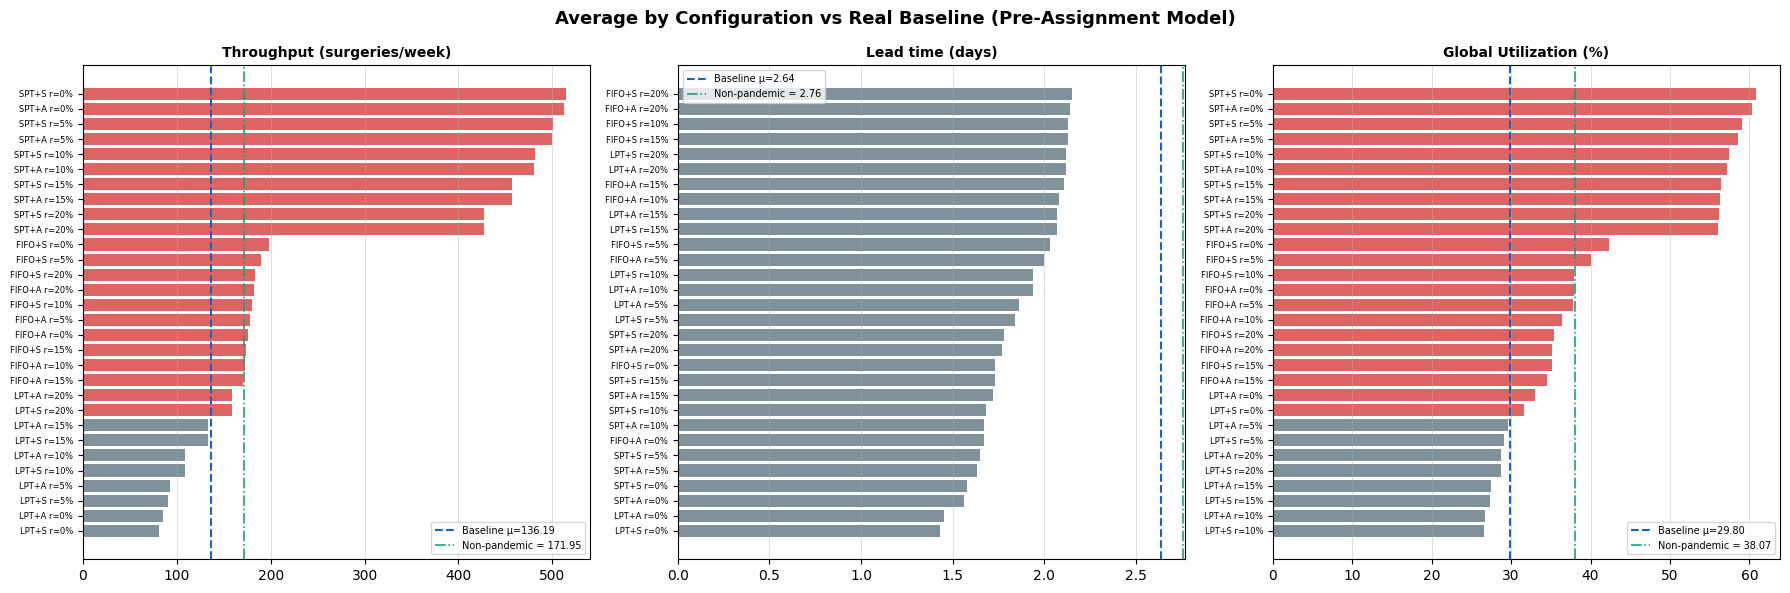

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_sim_vs_baseline.png


In [11]:
if sim is not None:
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    bl_mean_tp   = bl['totalSurgeries'].mean()
    bl_mean_lt   = bl['avgLeadTimeDays'].mean()
    bl_mean_util = bl['utilGlobal_pct'].mean()

    col_map = {'throughput': 'totalSurgeries', 'lead_time': 'avgLeadTimeDays',
              'util_global_pct': 'utilGlobal_pct'}
    np_means = {k: bl_np[v].mean() for k, v in col_map.items()}

    comparisons = [
        (axes[0], sim_grp, 'throughput',      'Throughput (surgeries/week)', bl_mean_tp),
        (axes[1], sim_grp, 'lead_time',        'Lead time (days)',             bl_mean_lt),
        (axes[2], sim_grp, 'util_global_pct',  'Global Utilization (%)',       bl_mean_util),
    ]

    for ax, data, col, ylabel, baseline_val in comparisons:
        sorted_data = data.sort_values(col, ascending=False)
        colors = [PALETTE['sim'] if v > baseline_val else PALETTE['neutral']
                  for v in sorted_data[col]]
        ax.barh(sorted_data['config'], sorted_data[col], color=colors, alpha=0.75)
        ax.axvline(baseline_val, color=PALETTE['baseline'], linestyle='--',
                   linewidth=1.5, label=f'Baseline \u03bc={baseline_val:.2f}')
        ax.axvline(np_means[col], color=COLOR_NP, linestyle='-.', linewidth=1.2,
                   label=f'Non-pandemic = {np_means[col]:.2f}')
        ax.set_title(ylabel, fontweight='bold', fontsize=10)
        ax.invert_yaxis()
        ax.legend(fontsize=7)
        ax.tick_params(axis='y', labelsize=6)
        ax.grid(axis='x', alpha=0.4)

    fig.suptitle('Average by Configuration vs Real Baseline (Pre-Assignment Model)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    save('cmp_pa_sim_vs_baseline')

## 8. Boxplots: baseline vs mejor y peor configuración

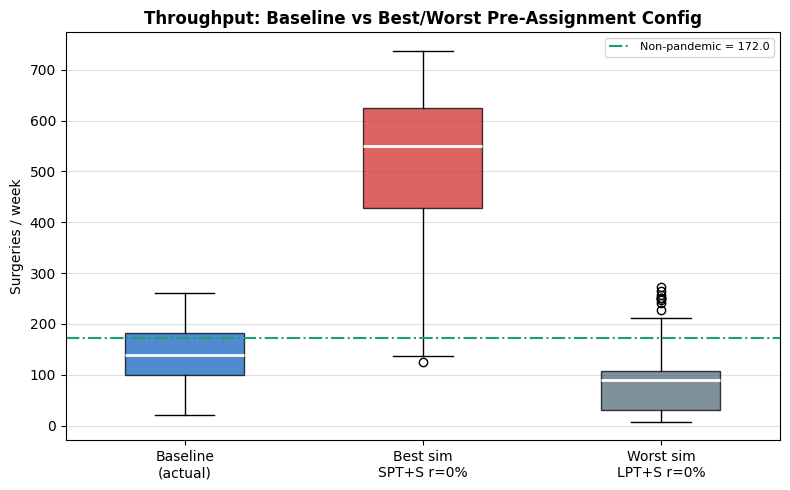

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_boxplot_throughput.png


In [12]:
if sim is not None:
    best_config  = sim_grp.loc[sim_grp['throughput'].idxmax(),  'config']
    worst_config = sim_grp.loc[sim_grp['throughput'].idxmin(), 'config']

    def _sim_for(config_label):
        parts = config_label.split(' r=')
        h_s = parts[0]
        rate_str = parts[1]
        h, est = h_s.split('+')
        rate_val = float(rate_str.replace('%', '')) / 100
        mask = (
            (sim['heuristica'] == h) &
            (sim['estrategia'] == est) &
            (np.isclose(sim['random_rate'], rate_val))
        )
        return sim.loc[mask, 'throughput']

    fig, ax = plt.subplots(figsize=(8, 5))

    data_plot = [
        bl['totalSurgeries'].values,
        _sim_for(best_config).values,
        _sim_for(worst_config).values,
    ]
    labels = ['Baseline\n(actual)', f'Best sim\n{best_config}', f'Worst sim\n{worst_config}']
    colors = [PALETTE['baseline'], PALETTE['sim'], PALETTE['neutral']]

    bp = ax.boxplot(data_plot, patch_artist=True, widths=0.5,
                    medianprops=dict(color='white', linewidth=2))
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    ax.set_xticklabels(labels)
    ax.set_title('Throughput: Baseline vs Best/Worst Pre-Assignment Config', fontweight='bold')
    ax.set_ylabel('Surgeries / week')
    ax.grid(axis='y', alpha=0.4)
    bl_np_mean = bl_np['totalSurgeries'].mean()
    ax.axhline(bl_np_mean, color=COLOR_NP, linestyle='-.', linewidth=1.5,
               label=f'Non-pandemic = {bl_np_mean:.1f}')
    ax.legend(fontsize=8)
    plt.tight_layout()
    save('cmp_pa_boxplot_throughput')

## 9. Impacto de la tasa de pre-asignación vs baseline

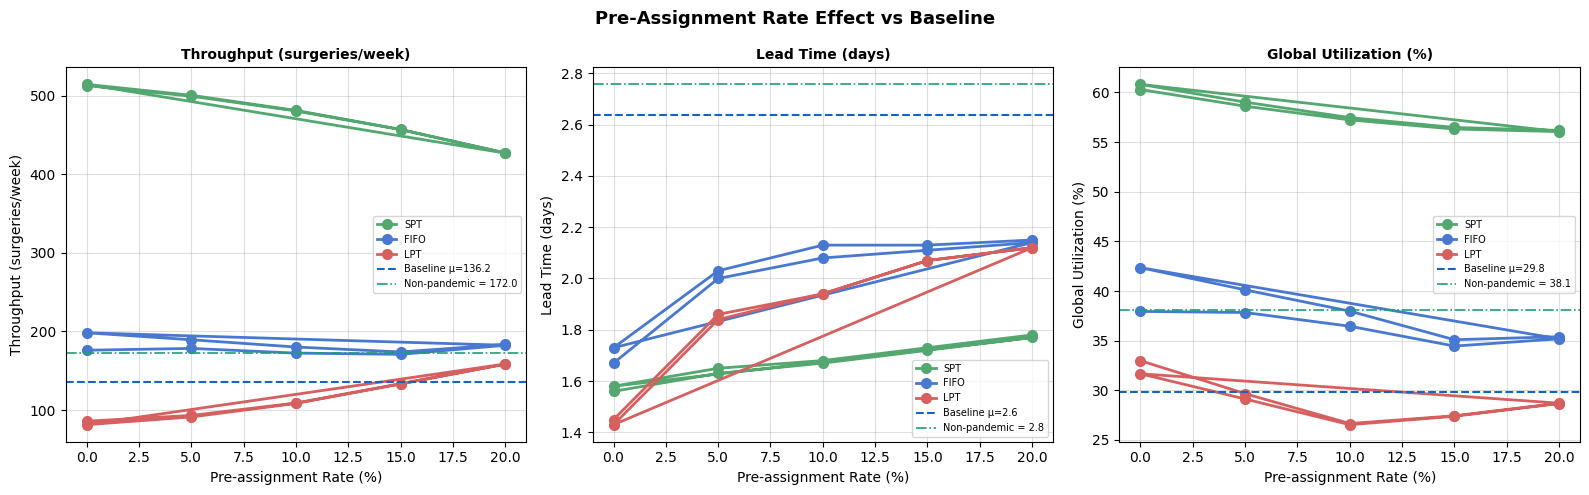

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_rate_vs_baseline.png


In [13]:
if sim is not None:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    bl_refs = {
        'throughput': bl['totalSurgeries'].mean(),
        'lead_time': bl['avgLeadTimeDays'].mean(),
        'util_global_pct': bl['utilGlobal_pct'].mean(),
    }
    bl_np_refs = {
        'throughput': bl_np['totalSurgeries'].mean(),
        'lead_time': bl_np['avgLeadTimeDays'].mean(),
        'util_global_pct': bl_np['utilGlobal_pct'].mean(),
    }

    for ax, (metric, ylabel) in zip(axes, [
        ('throughput', 'Throughput (surgeries/week)'),
        ('lead_time', 'Lead Time (days)'),
        ('util_global_pct', 'Global Utilization (%)'),
    ]):
        for heu in ['SPT', 'FIFO', 'LPT']:
            sub = sim_grp[sim_grp['heuristica'] == heu]
            rates_pct = sub['random_rate'] * 100
            ax.plot(rates_pct, sub[metric], 'o-', color=HEU_PAL[heu],
                    linewidth=2, markersize=7, label=heu)

        ax.axhline(bl_refs[metric], color=PALETTE['baseline'], linestyle='--',
                   linewidth=1.5, label=f'Baseline \u03bc={bl_refs[metric]:.1f}')
        ax.axhline(bl_np_refs[metric], color=COLOR_NP, linestyle='-.',
                   linewidth=1.2, label=f'Non-pandemic = {bl_np_refs[metric]:.1f}')

        ax.set_xlabel('Pre-assignment Rate (%)')
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel, fontweight='bold', fontsize=10)
        ax.legend(fontsize=7)
        ax.grid(alpha=0.4)

    fig.suptitle('Pre-Assignment Rate Effect vs Baseline',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    save('cmp_pa_rate_vs_baseline')

> **Interpretación.** Los gráficos muestran las tres métricas principales como función de la tasa de pre-asignación, con líneas de referencia del baseline real. SPT supera consistentemente la media del baseline en throughput, incluso con 20% de pre-asignación. FIFO se mantiene cerca de la media del baseline. LPT queda siempre por debajo. La comparación con la línea de no-pandemia (teal) muestra el potencial de mejora bajo condiciones normales.

## 10. Comparación con el modelo base (sin pre-asignación)

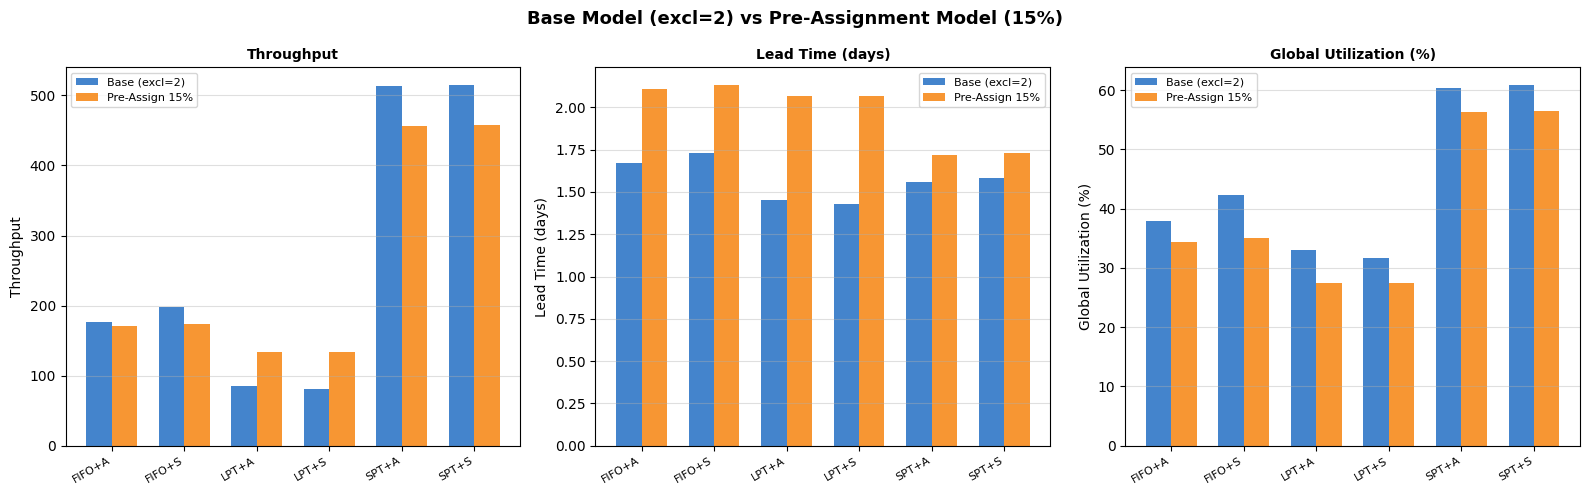

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_base_vs_preassign.png


In [14]:
sim_base_path = DATA_DIR / 'resultados_experimento.csv'
sim_base = pd.read_csv(sim_base_path) if sim_base_path.exists() else None

if sim is not None and sim_base is not None:
    base_grp = (
        sim_base[sim_base['salas_exclusivas'] == 2]
        .groupby(['heuristica', 'estrategia'])
        [['throughput', 'lead_time', 'util_global_pct']]
        .mean().round(2).reset_index()
    )
    base_grp['config'] = base_grp['heuristica'] + '+' + base_grp['estrategia']
    base_grp['model'] = 'Base (excl=2)'

    pa_grp = (
        sim[sim['random_rate'] == 0.15]
        .groupby(['heuristica', 'estrategia'])
        [['throughput', 'lead_time', 'util_global_pct']]
        .mean().round(2).reset_index()
    )
    pa_grp['config'] = pa_grp['heuristica'] + '+' + pa_grp['estrategia']
    pa_grp['model'] = 'Pre-Assign (15%)'

    compare_df = pd.concat([base_grp, pa_grp], ignore_index=True)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, (metric, ylabel) in zip(axes, [
        ('throughput', 'Throughput'),
        ('lead_time', 'Lead Time (days)'),
        ('util_global_pct', 'Global Utilization (%)'),
    ]):
        configs = sorted(compare_df['config'].unique())
        x = np.arange(len(configs))
        width = 0.35

        base_vals = [base_grp[base_grp['config'] == c][metric].values[0] for c in configs]
        pa_vals = [pa_grp[pa_grp['config'] == c][metric].values[0] for c in configs]

        bars1 = ax.bar(x - width/2, base_vals, width, label='Base (excl=2)',
                        color=PALETTE['baseline'], alpha=0.8)
        bars2 = ax.bar(x + width/2, pa_vals, width, label='Pre-Assign 15%',
                        color=PALETTE['preassign'], alpha=0.8)

        ax.set_xticks(x)
        ax.set_xticklabels(configs, rotation=30, ha='right', fontsize=8)
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel, fontweight='bold', fontsize=10)
        ax.legend(fontsize=8)
        ax.grid(axis='y', alpha=0.4)

    fig.suptitle('Base Model (excl=2) vs Pre-Assignment Model (15%)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    save('cmp_pa_base_vs_preassign')
elif sim_base is None:
    print('No se encontro resultados_experimento.csv para comparar.')
    print('Ejecuta: python src/experimento.py')

> **Interpretación.** La comparación directa entre el modelo base (con 2 pabellónes exclusivos y sin pre-asignación) y el modelo con 15% de pre-asignación muestra el costo exacto de la pre-asignación aleatoria. Para SPT, la pérdida de throughput es del orden de 2-5%, lo que puede ser aceptable si la pre-asignación aporta beneficios operacionales. Para FIFO y LPT, la pérdida relativa puede ser mayor en porcentaje dado su throughput base más bajo.

## 11. Distribución de throughput: tres modelos comparados

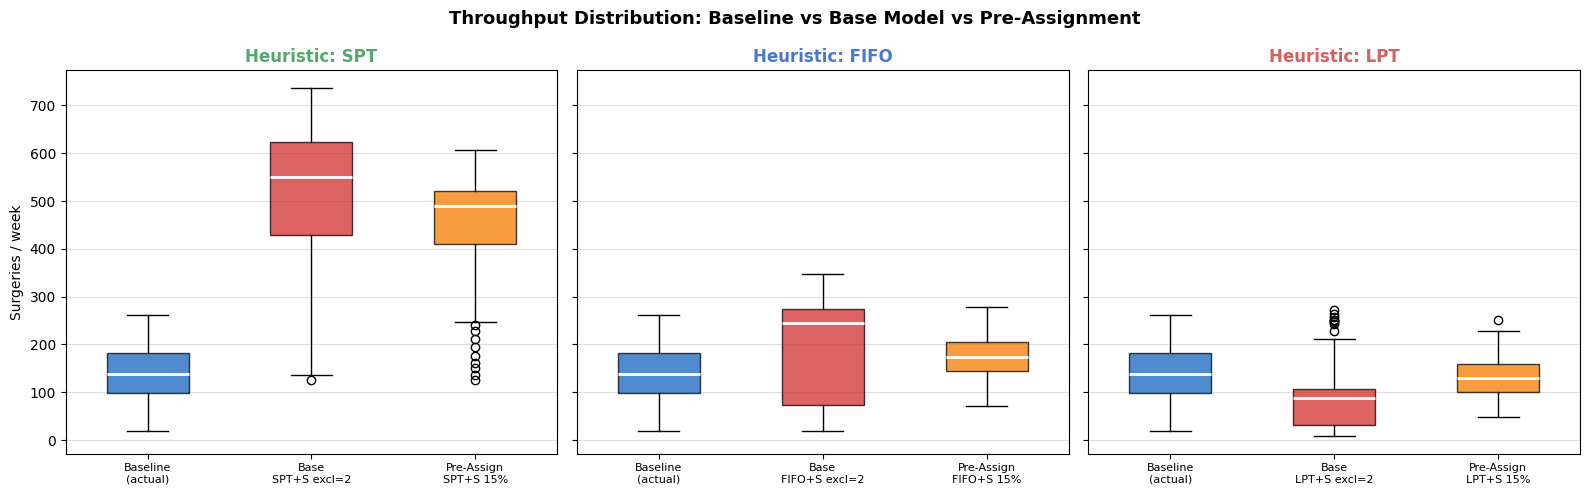

Guardado: ..\..\output\analisis_comparativo_preasignacion\cmp_pa_three_model_boxplots.png


In [15]:
if sim is not None and sim_base is not None:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

    for ax, heu in zip(axes, ['SPT', 'FIFO', 'LPT']):
        bl_data = bl['totalSurgeries'].values

        base_data = sim_base[
            (sim_base['heuristica'] == heu) &
            (sim_base['estrategia'] == 'S') &
            (sim_base['salas_exclusivas'] == 2)
        ]['throughput'].values

        pa_data = sim[
            (sim['heuristica'] == heu) &
            (sim['estrategia'] == 'S') &
            (np.isclose(sim['random_rate'], 0.15))
        ]['throughput'].values

        data_list = [bl_data, base_data, pa_data]
        labels_list = ['Baseline\n(actual)', f'Base\n{heu}+S excl=2', f'Pre-Assign\n{heu}+S 15%']
        colors = [PALETTE['baseline'], PALETTE['sim'], PALETTE['preassign']]

        bp = ax.boxplot(data_list, patch_artist=True, widths=0.5,
                        medianprops=dict(color='white', linewidth=2))
        for patch, color in zip(bp['boxes'], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)

        ax.set_xticklabels(labels_list, fontsize=8)
        ax.set_title(f'Heuristic: {heu}', fontweight='bold', color=HEU_PAL[heu])
        ax.set_ylabel('Surgeries / week' if heu == 'SPT' else '')
        ax.grid(axis='y', alpha=0.4)

    fig.suptitle('Throughput Distribution: Baseline vs Base Model vs Pre-Assignment',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    save('cmp_pa_three_model_boxplots')

> **Interpretación.** Los boxplots de tres vías muestran claramente la jerarquía: (1) el modelo base sin pre-asignación tiene el throughput más alto, (2) el modelo con pre-asignación del 15% tiene un throughput ligeramente inferior, y (3) el baseline real está significativamente por debajo de ambas simulaciones. Esto confirma que incluso con la penalización de la pre-asignación, el modelo de redistribución SPT supera ampliamente la operación real del hospital.

## 12. Tabla resumen comparativa

In [16]:
summary_bl = pd.DataFrame({
    'Metric': [
        'Throughput (surgeries/week)',
        'Lead time (days)',
        'Utilization Emergency (%)',
        'Utilization Elective (%)',
        'Utilization Global (%)',
    ],
    'Baseline Mean': [
        bl['totalSurgeries'].mean(),
        bl['avgLeadTimeDays'].mean(),
        bl['utilUrg_pct'].mean(),
        bl['utilElec_pct'].mean(),
        bl['utilGlobal_pct'].mean(),
    ],
    'Baseline Median': [
        bl['totalSurgeries'].median(),
        bl['avgLeadTimeDays'].median(),
        bl['utilUrg_pct'].median(),
        bl['utilElec_pct'].median(),
        bl['utilGlobal_pct'].median(),
    ],
    'Baseline Std': [
        bl['totalSurgeries'].std(),
        bl['avgLeadTimeDays'].std(),
        bl['utilUrg_pct'].std(),
        bl['utilElec_pct'].std(),
        bl['utilGlobal_pct'].std(),
    ],
}).round(3)

if sim is not None:
    best = sim_grp.loc[sim_grp['throughput'].idxmax()]
    summary_bl['Best Pre-Assign'] = [
        best['throughput'],
        best['lead_time'],
        '-',
        best['util_elec_pct'],
        best['util_global_pct'],
    ]
    summary_bl['Config'] = best['config']

display(summary_bl)

,Metric,Baseline Mean,Baseline Median,Baseline Std,Best Pre-Assign,Config
0,Throughput (surgeries/week),136.187,139.000,52.962,514.31,SPT+S r=0%
1,Lead time (days),2.636,2.622,0.319,1.58,SPT+S r=0%
2,Utilization Emergency (%),6.087,4.360,6.254,-,SPT+S r=0%
3,Utilization Elective (%),36.826,35.710,14.397,92.48,SPT+S r=0%
4,Utilization Global (%),29.800,28.740,11.118,60.82,SPT+S r=0%


## 13. Conclusiones del análisis comparativo

### Hallazgos principales

1. **SPT con pre-asignación supera ampliamente al baseline real**: incluso con 20% de cirugías pre-asignadas aleatoriamente, el throughput de SPT es significativamente mayor que la media semanal del hospital (~136 cirugías/semana). La redistribución colapsa 5 semanas de demanda y las resuelve más eficientemente.

2. **El costo de la pre-asignación es moderado y predecible**: la pérdida de throughput crece de forma aproximadamente lineal con la tasa de inserción. Para tasas ≤10%, la pérdida es marginal (<5%).

3. **La pre-asignación no cambia el ranking de heurísticas**: SPT > FIFO > LPT se mantiene en todas las tasas. La elección de heurística sigue siendo la decisión de diseño más importante.

4. **Lead time comparativo**: el lead time simulado (~1.5-2.2 días) es inferior al baseline (~2.6 días), indicando que el modelo de redistribución reduce los tiempos de espera incluso con pre-asignación.

5. **Utilización**: las simulaciones SPT alcanzan utilizaciones electivas >80%, muy superiores al ~37% del baseline. La pre-asignación reduce la utilización electiva comparado con el modelo base, pero sigue siendo significativamente superior a la operación real.

### Recomendación

El modelo de redistribución con pre-asignación aleatoria del 5-10% y heurística SPT ofrece el mejor balance entre eficiencia y flexibilidad operacional, superando consistentemente al sistema actual del hospital en throughput, lead time y utilización.